# Fase 4 · Visualización y comunicación de resultados
## Licitaciones públicas de ChileCompra · MCDI500 · Grupo 2

Este cuaderno desarrolla y verifica la Fase 4 a partir de las salidas consolidadas en `data/processed/`, respondiendo las preguntas definidas en `F1/F1_Definicion.ipynb` (sección 3):

1. **Coincidencia y brecha por moneda:** en qué proporción de las licitaciones comparables coincide el monto estimado registrado con el total de las ofertas ganadoras y, cuando difieren, cuál es el sentido y la magnitud de la brecha en cada moneda (`CLP`, `CLF`, `USD`, `UTM`).
2. **Comparación según tamaño del proveedor ganador:** cómo cambian la coincidencia y la brecha según `TamanoProveedorOrdinal` (`Micro < Pequeña < Mediana < Grande`, manteniendo `NoClasificado` fuera de la escala).

**Flujo del cuaderno (F1–F4).** Siguiendo `docs/arquitectura.md`, toda la lógica de indicadores y gráficos reside en **`src/comunicacion.py`**:
1. **Entorno, configuración y estilo de figuras** (`sys.prefix`, `requirements.txt` y `plt.rcParams` definido una vez).
2. **Carga de artefactos y contrato de verificación** (`cargar_artefactos` con `sep=";"` y `usecols`, y `assert` contra `diccionario_f3.csv` y `parametros_f3.csv`).
3. **Verificación independiente contra `data/raw`** (recálculo directo desde el CSV original sobre una muestra diversa).
4. **Copia interpretable para graficar y tabla de vinculación Objetivo · Pregunta · Figura**.
5. **Tres figuras principales (`200 ppp`)**, una por objetivo específico de F1 (con contexto de OE1, título con hallazgo, unidades, fuente y lectura debajo).
6. **Control de variable de confusión:** tamaño ganador estratificado dentro de `TramoEstimado`.
7. **Exportación reproducible** de `docs/hallazgos_f4.csv` y `docs/metadatos_f4.json`.

**Cómo ejecutar.** Genera primero `data/processed/` (`F2` y `F3`) y ejecuta todas las celdas con el kernel **Python (grupo2-mcdi500)**.


## 1. Entorno, configuración y estilo de figuras

Comprueba que el cuaderno se ejecuta dentro del entorno virtual `.venv` mediante `sys.prefix != sys.base_prefix`, valida las versiones declaradas en `requirements.txt` (`pandas`, `numpy`, `matplotlib`, `scipy`, `pytest`; sin `seaborn`), importa `src/comunicacion.py`, verifica la presencia de los cuatro artefactos en `data/processed/` y fija **una única vez** el estilo global de figuras (`plt.rcParams`).


In [1]:
%matplotlib inline
# 1) Entorno con sys.prefix, configuración de rutas y estilo global de figuras.
import json
import math
import platform
import sys
from importlib import metadata
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

PAQUETES_F4 = ["pandas", "numpy", "matplotlib", "scipy", "pytest"]

inicio = Path.cwd().resolve()
raiz = next((p for p in (inicio, *inicio.parents) if (p / "requirements.txt").is_file()), None)
if raiz is None:
    raise FileNotFoundError("No se encontró requirements.txt: abre el notebook dentro del repositorio.")
assert sys.prefix != sys.base_prefix, "No se usa un entorno virtual: cambia el kernel a 'Python (grupo2-mcdi500)'."
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

from src.comunicacion import (
    ARCHIVOS_PROCESADOS,
    COLUMNAS_LICITACIONES_F4,
    COLUMNAS_OFERTAS_F4,
    ORDEN_SENTIDO,
    asignar_tamano_ganador,
    cargar_artefactos,
    construir_copia_graficar,
    graficar_cajas_brecha_relativa,
    graficar_coincidencia_por_tamano,
    graficar_razon_escala_log,
    guardar_figura,
    intervalo_wilson,
    preparar_comparables,
    resumen_magnitud_por_moneda,
    resumen_sentido_por_moneda,
    tabla_control_confusion,
    tabla_resumen_por_tamano,
)
from src.preprocesamiento import ORDEN_TAMANO, normalizar_codigo, verificar_hash_raw

declaradas = {}
for linea in (raiz / "requirements.txt").read_text(encoding="utf-8").splitlines():
    nombre, _, ver = linea.strip().partition("==")
    if nombre.lower() in PAQUETES_F4:
        declaradas[nombre.lower()] = ver

versiones_f4 = pd.DataFrame([
    {
        "Paquete": pkg,
        "Declarada": declaradas.get(pkg),
        "Instalada": metadata.version(pkg),
        "Coincide": metadata.version(pkg) == declaradas.get(pkg),
    }
    for pkg in PAQUETES_F4
])

ESTILO_FIGURAS_F4 = {
    "figure.dpi": 120,
    "savefig.dpi": 150,
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.linestyle": "--",
    "grid.alpha": 0.35,
    "legend.frameon": True,
}
plt.rcParams.update(ESTILO_FIGURAS_F4)

carpeta_procesados = raiz / "data/processed"
carpeta_figuras = raiz / "F4/figuras"
ruta_raw = raiz / "data/raw/04LicitacionesEne.csv"
for clave, archivo in ARCHIVOS_PROCESADOS.items():
    ruta_art = carpeta_procesados / archivo
    if not ruta_art.is_file():
        raise FileNotFoundError(f"Falta {ruta_art.relative_to(raiz)}. Ejecuta F2 y F3 primero.")

print(f"Intérprete: {Path(sys.executable).relative_to(raiz)} | Python {platform.python_version()} | {platform.system()}")
print(f"sys.prefix      : {sys.prefix}")
print(f"sys.base_prefix : {sys.base_prefix}")
print("[OK] Entorno virtual activo y estilo global plt.rcParams definido una vez.")
assert versiones_f4["Coincide"].all(), "Hay versiones distintas a requirements.txt"
display(versiones_f4)


Intérprete: .venv\Scripts\python.exe | Python 3.15.2 | Windows
sys.prefix      : C:\Users\danie\Desktop\proyecto-grupo2-mcdi500\.venv
sys.base_prefix : C:\Program Files\Python315
[OK] Entorno virtual activo y estilo global plt.rcParams definido una vez.


,Paquete,Declarada,Instalada,Coincide
0,pandas,3.1.0,3.1.0,True
1,numpy,2.5.4,2.5.4,True
2,matplotlib,3.11.2,3.11.2,True
3,scipy,1.18.1,1.18.1,True
4,pytest,9.2.0,9.2.0,True


## 2. Carga de artefactos y contrato con `assert`

Carga los cuatro archivos de `data/processed/` con `cargar_artefactos()` (`sep=";"` y `usecols`), tipa explícitamente las columnas booleanas con valores faltantes (`EsExtremoLogIQR_CLP` y `CoincideConEstimado`) y verifica por contrato (`assert`) contra `diccionario_f3.csv` y `parametros_f3.csv`:

- **Esquema:** coincidencia exacta entre los encabezados de cada archivo CSV (`17` y `24` columnas) y las `41` entradas de `diccionario_f3.csv`.
- **Cardinalidad e integridad:** `45.741` ofertas, `2.292` licitaciones únicas (`NroLicitacion`), mismo conjunto de códigos en ambas tablas y consistencia con `ofertas_validas = 45.603` de `parametros_f3.csv`.
- **Tipos de datos:** compatibilidad de cada columna cargada frente al `Tipo en Python` declarado en `diccionario_f3.csv`.


In [2]:
# 2) Carga selectiva (usecols) de artefactos y validación de contrato contra diccionario_f3 y parametros_f3.
artefactos = cargar_artefactos(carpeta_procesados)
ofertas_f4 = artefactos.ofertas.copy()
licitaciones_f4 = artefactos.licitaciones.copy()
diccionario = artefactos.diccionario
parametros = artefactos.parametros

# Restaurar tipo nullable boolean de diccionario_f3 para columnas con <NA>.
ofertas_f4["EsExtremoLogIQR_CLP"] = ofertas_f4["EsExtremoLogIQR_CLP"].astype("boolean")
licitaciones_f4["CoincideConEstimado"] = licitaciones_f4["CoincideConEstimado"].astype("boolean")

# 2.1 Contrato de esquema completo (archivos vs diccionario_f3.csv).
cols_archivo_ofertas = pd.read_csv(carpeta_procesados / ARCHIVOS_PROCESADOS["ofertas"], sep=";", encoding="utf-8-sig", nrows=0).columns.tolist()
cols_archivo_lic = pd.read_csv(carpeta_procesados / ARCHIVOS_PROCESADOS["licitaciones"], sep=";", encoding="utf-8-sig", nrows=0).columns.tolist()
dic_ofertas = diccionario.loc[diccionario["Tabla"].eq("ofertas")].set_index("Columna")
dic_lic = diccionario.loc[diccionario["Tabla"].eq("licitaciones")].set_index("Columna")

assert set(cols_archivo_ofertas) == set(dic_ofertas.index), "Desajuste de esquema en ofertas vs diccionario_f3"
assert set(cols_archivo_lic) == set(dic_lic.index), "Desajuste de esquema en licitaciones vs diccionario_f3"
assert set(COLUMNAS_OFERTAS_F4) == set(ofertas_f4.columns)
assert set(COLUMNAS_LICITACIONES_F4) == set(licitaciones_f4.columns)
assert len(diccionario) == len(cols_archivo_ofertas) + len(cols_archivo_lic) == 41

# 2.2 Contrato de filas e integridad referencial.
assert len(ofertas_f4) == 45741, f"Se esperaban 45.741 ofertas y hay {len(ofertas_f4)}"
assert len(licitaciones_f4) == 2292, f"Se esperaban 2.292 licitaciones y hay {len(licitaciones_f4)}"
assert licitaciones_f4["NroLicitacion"].is_unique, "NroLicitacion repetido en licitaciones"
assert set(normalizar_codigo(ofertas_f4["NroLicitacion"]).dropna()) == set(normalizar_codigo(licitaciones_f4["NroLicitacion"]))
ofertas_clp_param = int(float(parametros.loc[parametros["Parámetro"].eq("ofertas_validas"), "Valor"].iloc[0]))
assert int(ofertas_f4["EsExtremoLogIQR_CLP"].notna().sum()) == ofertas_clp_param == 45603

# 2.3 Contrato de tipos frente a diccionario_f3['Tipo en Python'].
def _tipo_compatible(serie: pd.Series, tipo_dic: str) -> bool:
    if tipo_dic in {"Float64", "Int64", "int64"}:
        return pd.api.types.is_numeric_dtype(serie.dtype)
    if tipo_dic in {"boolean", "bool"}:
        return pd.api.types.is_bool_dtype(serie.dtype)
    if tipo_dic == "category":
        return isinstance(serie.dtype, pd.CategoricalDtype) and serie.cat.ordered and tuple(serie.cat.categories) == ORDEN_TAMANO
    if tipo_dic in {"string", "str"}:
        return pd.api.types.is_string_dtype(serie.dtype)
    return False

for col in ofertas_f4.columns:
    tipo_esp = str(dic_ofertas.loc[col, "Tipo en Python"])
    assert _tipo_compatible(ofertas_f4[col], tipo_esp), f"Tipo incompatible en ofertas[{col}]: {ofertas_f4[col].dtype} vs {tipo_esp}"
for col in licitaciones_f4.columns:
    tipo_esp = str(dic_lic.loc[col, "Tipo en Python"])
    assert _tipo_compatible(licitaciones_f4[col], tipo_esp), f"Tipo incompatible en licitaciones[{col}]: {licitaciones_f4[col].dtype} vs {tipo_esp}"

resumen_contrato = pd.DataFrame([
    {
        "Tabla": "ofertas",
        "Filas": len(ofertas_f4),
        "Columnas archivo": len(cols_archivo_ofertas),
        "Columnas usecols": ofertas_f4.shape[1],
        "Esquema diccionario_f3": "OK",
        "Tipos": "OK",
    },
    {
        "Tabla": "licitaciones",
        "Filas": len(licitaciones_f4),
        "Columnas archivo": len(cols_archivo_lic),
        "Columnas usecols": licitaciones_f4.shape[1],
        "Esquema diccionario_f3": "OK",
        "Tipos": "OK",
    },
])
print("[OK] Contrato de esquema (41 columnas), cardinalidad (45.741 / 2.292), parámetros (45.603 CLP) y tipos verificado.")
display(resumen_contrato)


[OK] Contrato de esquema (41 columnas), cardinalidad (45.741 / 2.292), parámetros (45.603 CLP) y tipos verificado.


,Tabla,Filas,Columnas archivo,Columnas usecols,Esquema diccionario_f3,Tipos
0,ofertas,45741,17,10,OK,OK
1,licitaciones,2292,24,11,OK,OK


## 3. Verificación independiente contra `data/raw`

Para descartar errores de arrastre entre fases, si el archivo original `data/raw/04LicitacionesEne.csv` está disponible localmente, se lee directamente con `sep=";"` y `encoding="latin-1"` de manera independiente a `src/comunicacion.py` y se recalcula desde cero:

- Cantidad total de filas (`45.741`) y licitaciones únicas (`2.292`).
- **En una muestra determinista de `7` licitaciones comparables** (que abarca coincidencia exacta, brecha negativa, brecha positiva, múltiples ofertas ganadoras —desde `1` hasta `114` ítems— y las monedas `CLP`, `CLF` y `USD`): cantidad de ganadoras, `MontoTotalGanadoras` sumado desde las filas crudas (con conversión directa de coma decimal) y `BrechaMonto`, comprobando con `assert` su coincidencia frente a `artefactos.licitaciones`.


In [3]:
# 3) Verificación independiente contra data/raw recalculando una muestra desde el CSV original.
verificacion_raw = {"disponible": bool(ruta_raw.is_file()), "muestra": 0, "estado": "OMITIDA (sin CSV crudo local)"}

if ruta_raw.is_file():
    hash_raw_verificado = verificar_hash_raw(ruta_raw)
    crudo = pd.read_csv(
        ruta_raw,
        sep=";",
        encoding="latin-1",
        usecols=["NroLicitacion", "ResultadoOferta", "MontoTotalOferta", "MontoEstimadoLicitacion", "MonedaLicitacion"],
        dtype="string",
    )
    assert len(crudo) == len(ofertas_f4) == 45741
    crudo["Nro_norm"] = crudo["NroLicitacion"].str.strip().str.upper()
    assert crudo["Nro_norm"].nunique() == len(licitaciones_f4) == 2292

    comp_proc = licitaciones_f4.loc[licitaciones_f4["EstadoBrecha"].eq("Calculada")].copy()
    candidatos = [
        comp_proc.loc[comp_proc["CoincideConEstimado"].fillna(False) & comp_proc["OfertasGanadoras"].eq(1), "NroLicitacion"].iloc[0],
        comp_proc.loc[comp_proc["CoincideConEstimado"].fillna(False) & comp_proc["OfertasGanadoras"].gt(1), "NroLicitacion"].iloc[0],
        comp_proc.loc[comp_proc["BrechaMonto"].lt(0) & comp_proc["MonedaLicitacion"].eq("CLP"), "NroLicitacion"].iloc[0],
        comp_proc.loc[comp_proc["BrechaMonto"].gt(0) & comp_proc["MonedaLicitacion"].eq("CLP"), "NroLicitacion"].iloc[0],
        comp_proc.loc[comp_proc["BrechaMonto"].gt(0) & comp_proc["OfertasGanadoras"].gt(3), "NroLicitacion"].iloc[0],
        comp_proc.loc[comp_proc["BrechaMonto"].lt(0) & comp_proc["OfertasGanadoras"].gt(3), "NroLicitacion"].iloc[0],
        comp_proc.loc[comp_proc["MonedaLicitacion"].eq("CLF"), "NroLicitacion"].iloc[0],
        comp_proc.loc[comp_proc["MonedaLicitacion"].eq("USD"), "NroLicitacion"].iloc[0],
    ]
    muestra_ids = list(dict.fromkeys(candidatos))

    sub_raw = crudo.loc[crudo["Nro_norm"].isin(muestra_ids)].copy()
    sub_raw["MontoTotalNum"] = pd.to_numeric(sub_raw["MontoTotalOferta"].str.strip().str.replace(",", ".", regex=False), errors="raise")
    sub_raw["EstimadoNum"] = pd.to_numeric(sub_raw["MontoEstimadoLicitacion"].str.strip().str.replace(",", ".", regex=False), errors="raise")
    sub_raw["EsGanadora"] = sub_raw["ResultadoOferta"].str.strip().str.casefold().eq("ganadora")

    filas_verif = []
    proc_idx = comp_proc.set_index("NroLicitacion")
    for lic_id in muestra_ids:
        g_raw = sub_raw.loc[sub_raw["Nro_norm"].eq(lic_id)]
        gan_raw = g_raw.loc[g_raw["EsGanadora"]]
        total_gan_raw = float(gan_raw["MontoTotalNum"].sum())
        est_raw = float(g_raw["EstimadoNum"].iloc[0])
        brecha_raw = total_gan_raw - est_raw
        n_gan_raw = int(len(gan_raw))

        fila_proc = proc_idx.loc[lic_id]
        assert n_gan_raw == int(fila_proc["OfertasGanadoras"]), f"Diferencia en ganadoras para {lic_id}"
        assert math.isclose(total_gan_raw, float(fila_proc["MontoTotalGanadoras"]), rel_tol=1e-12, abs_tol=1e-6)
        assert math.isclose(brecha_raw, float(fila_proc["BrechaMonto"]), rel_tol=1e-12, abs_tol=1e-6)

        filas_verif.append({
            "NroLicitacion": lic_id,
            "Moneda": fila_proc["MonedaLicitacion"],
            "Ganadoras_raw": n_gan_raw,
            "TotalGanadoras_raw": total_gan_raw,
            "TotalGanadoras_proc": float(fila_proc["MontoTotalGanadoras"]),
            "Brecha_raw": brecha_raw,
            "Brecha_proc": float(fila_proc["BrechaMonto"]),
            "Diferencia_abs": abs(brecha_raw - float(fila_proc["BrechaMonto"])),
        })

    tabla_verif_raw = pd.DataFrame(filas_verif)
    verificacion_raw = {
        "disponible": True,
        "filas_crudo": int(len(crudo)),
        "licitaciones_unicas_crudo": int(crudo["Nro_norm"].nunique()),
        "muestra_licitaciones": len(tabla_verif_raw),
        "max_diferencia_abs": float(tabla_verif_raw["Diferencia_abs"].max()),
        "sha256_lf": hash_raw_verificado,
        "estado": "APROBADA",
    }
    print(f"[OK] Verificación contra data/raw aprobada sobre {len(tabla_verif_raw)} licitaciones (máxima diferencia={verificacion_raw['max_diferencia_abs']:.1e}).")
    display(tabla_verif_raw.round(4))
else:
    print("[AVISO] No se encontró data/raw/04LicitacionesEne.csv localmente; se omite la verificación contra el CSV original.")


[OK] Verificación contra data/raw aprobada sobre 7 licitaciones (máxima diferencia=0.0e+00).


,NroLicitacion,Moneda,Ganadoras_raw,TotalGanadoras_raw,TotalGanadoras_proc,Brecha_raw,Brecha_proc,Diferencia_abs
0,4080-31-LP24,CLP,1,56317830.0,56317830.0,0.0,0.0,0.0
1,2366-168-LE24,CLP,9,13210200.0,13210200.0,0.0,0.0,0.0
2,2410-128-LP24,CLP,2,2.0,2.0,-71499998.0,-71499998.0,0.0
3,2366-129-L124,CLP,16,11758244.0,11758244.0,8127774.0,8127774.0,0.0
4,2709-190-LR24,CLP,114,7532080.0,7532080.0,-62299448.0,-62299448.0,0.0
5,2410-201-LQ24,CLF,1,4140.0,4140.0,-787.0,-787.0,0.0
6,584146-1-LP25,USD,1,89376.0,89376.0,0.0,0.0,0.0


## 4. Copia interpretable para graficar y vinculación con objetivos

En flujos donde el preprocesamiento estandariza o codifica numéricamente las variables, suele requerirse separar una matriz transformada de una copia interpretable con unidades y etiquetas originales. En este proyecto, **F2 y F3 no aplicaron escalamiento ni codificación entera**: conservaron los montos en su moneda original (`CLP`, `CLF`, `USD`, `UTM`) y las categorías en texto (`TamanoProveedor` y `TamanoProveedorOrdinal`). Por ello **no aplican** funciones como `revertir_escalamiento` ni `reconstruir_categorias` (decisión registrada en `docs/decisiones.md`).

La copia `copia_graficar` parte de las tablas ya preparadas por `src/comunicacion.py` (`preparar_comparables()` y `asignar_tamano_ganador()`) y **únicamente añade atributos interpretables para visualización**:

1. **Etiquetas legibles:** `EtiquetaCoincidencia` (`"Coincide"` frente a `"Difiere"`), `SentidoBrecha` (`"Bajo el estimado"`, `"Coincide"`, `"Sobre el estimado"`) y `TamanoGanador` (incluyendo `"Múltiple"` cuando concurren varios tamaños ganadores).
2. **Tramos de monto estimado (`TramoEstimado`):** cuatro rangos legibles en `CLP` (`Hasta 1 M CLP`, `1 a 10 M CLP`, `10 a 50 M CLP`, `Más de 50 M CLP`) y la etiqueta explícita `"Otra moneda (no CLP)"` para no mezclar unidades.
3. **Brecha relativa (`BrechaRelativaPct`):** `(BrechaMonto / MontoEstimadoLicitacion) * 100`, complementando `RazonMonto` y `LogRazonMonto`.
4. **`NoClasificado` fuera del eje ordinal:** `TamanoGanadorOrdinal` conserva estrictamente `Micro < Pequeña < Mediana < Grande`; tanto `NoClasificado` como `Múltiple` permanecen como `<NA>` en el eje ordinal y se reportan aparte en `TamanoGanador`.


In [4]:
# 4) Construir copia interpretable para graficar usando src/comunicacion.py (sin revertir escalamiento).
copia_graficar = construir_copia_graficar(licitaciones_f4, ofertas_f4)

fuera_ordinal = copia_graficar["TamanoGanador"].isin(["NoClasificado", "Múltiple"])
assert copia_graficar.loc[fuera_ordinal, "TamanoGanadorOrdinal"].isna().all(), "NoClasificado/Múltiple no deben entrar al eje ordinal"
assert tuple(copia_graficar["TamanoGanadorOrdinal"].cat.categories) == ORDEN_TAMANO
assert copia_graficar["BrechaRelativaPct"].notna().all()

print(f"[OK] copia_graficar construida: {copia_graficar.shape[0]:,} licitaciones × {copia_graficar.shape[1]} columnas")
display(copia_graficar["TramoEstimado"].value_counts(sort=False).to_frame("Licitaciones"))
display(copia_graficar.groupby(["TamanoGanador", "TamanoGanadorOrdinal"], dropna=False, observed=False).size().loc[lambda s: s > 0].to_frame("Licitaciones"))


[OK] copia_graficar construida: 2,257 licitaciones × 19 columnas


,Licitaciones
TramoEstimado,
Hasta 1 M CLP,350
1 a 10 M CLP,739
10 a 50 M CLP,783
Más de 50 M CLP,358
Otra moneda (no CLP),27


,,Licitaciones
TamanoGanador,TamanoGanadorOrdinal,
Grande,Grande,365
Mediana,Mediana,273
Micro,Micro,405
Múltiple,nan,240
NoClasificado,nan,284
Pequeña,Pequeña,690


### 4.1. Tabla de vinculación: objetivo, pregunta y figura

Cada figura de la sección 5 responde directamente a los objetivos específicos y preguntas de `F1/F1_Definicion.ipynb` (sin gráficos ajenos a esos objetivos), y se complementa con el control de confusión de la sección 6:

| Objetivo específico (F1) | Pregunta de investigación (F1) | Figura / evidencia en F4 | Sección y función en `src/comunicacion.py` |
| :--- | :--- | :--- | :--- |
| **OE1 + OE3 (coincidencia):** Proporción de coincidencia global y comparación según tamaño ganador | **P1 (parte 1) y P2 (coincidencia):** Tasa global (`55,6 %`, `1.254/2.257`) en el título y la línea naranja; contraste por tamaño con IC Wilson | **Figura 1:** Barras de coincidencia por tamaño con IC `95 %` Wilson y línea naranja OE1 en `55,6 %` (`01_coincidencia_por_tamano.png`) | Sección `5.1` · `tabla_resumen_por_tamano(..., moneda=None)` + `graficar_coincidencia_por_tamano()` |
| **OE2:** Magnitud y sentido de la brecha cuando difieren, por moneda | **P1 (parte 2):** Magnitud relativa y concentración de razones | **Figura 2:** Histograma de `MontoTotalGanadoras / MontoEstimadoLicitacion` en escala logarítmica con marcas en `1` y `1/1,19` (`02_razon_ganador_estimado_log.png`) | Sección `5.2` · `resumen_magnitud_por_moneda()` + `graficar_razon_escala_log()` |
| **OE3 (brecha):** Dispersión y magnitud de la brecha según tamaño ganador (complementa a Figura 1) | **P2 (brecha):** Variación de la brecha relativa según tamaño del proveedor ganador (`n` por categoría) | **Figura 3:** Cajas de `BrechaRelativaPct` (`%`) por tamaño con `n` por categoría (`03_cajas_brecha_relativa_tamano.png`) | Sección `5.3` · `graficar_cajas_brecha_relativa()` |
| **Control metodológico (OE3):** Comparar dentro de tramos de monto | ¿Persiste el efecto del tamaño ganador dentro de procesos de monto similar? | Tabla estratificada `TamanoGanador` dentro de `TramoEstimado` en `CLP` (`n = 1.710`) | Sección `6` · `tabla_control_confusion()` |

### 4.1. Medición de la tabla por licitación con tamaño ganador

Se mide la asignación de `TamanoGanador` y `TamanoGanadorOrdinal` a la tabla ya agregada por licitación. La referencia recorre las ofertas y las licitaciones fila por fila. La versión de F4 agrupa las ofertas ganadoras y asigna el tamaño mediante un mapeo de pandas. Ambas comparten la normalización de códigos y devuelven la tabla completa.

Cada tamaño usa un prefijo de las ofertas procesadas y las licitaciones cuyos códigos aparecen en ese prefijo. En los prefijos parciales, el tamaño se determina a partir de las ganadoras presentes en el prefijo. Estas muestras sirven para medir la operación. El análisis de OE2 y OE3 conserva su universo original. La carga y selección de datos quedan fuera de la medición.

Se reutiliza el método de F3 (§ 4.2), con el mínimo de siete tiempos y el menor pico de siete ejecuciones independientes de memoria rastreada por Python. `pandas.testing.assert_frame_equal(check_exact=True)` verifica la tabla completa, incluidos índice, orden, tipos y categoría ordinal.

En la ejecución guardada, la iterativa gana por 0,454 ms con 1.000 ofertas. A partir de 5.000, la versión vectorizada gana y su ventaja crece hasta 2,80× con 45.741 ofertas. La inversión se observa entre los dos primeros tamaños. El agrupamiento tiene un costo fijo que pesa más con entradas pequeñas y evita el recorrido por filas que se encarece al crecer la muestra. La vectorizada registra menos memoria pico en los cuatro tamaños.

In [5]:
from src.comunicacion import asignar_tamano_ganador_iterativo
from src.medicion import medir_contraste

codigos_licitaciones = normalizar_codigo(licitaciones_f4["NroLicitacion"])
mediciones_tamano = []
for n_filas in (1_000, 5_000, 20_000, 45_741):
    ofertas_muestra = ofertas_f4.iloc[:n_filas]
    assert len(ofertas_muestra) == n_filas
    codigos_muestra = normalizar_codigo(ofertas_muestra["NroLicitacion"])
    licitaciones_muestra = licitaciones_f4.loc[codigos_licitaciones.isin(codigos_muestra)]
    mediciones_tamano.append({
        "Filas de oferta": n_filas,
        "Licitaciones": len(licitaciones_muestra),
        **medir_contraste(
            lambda: asignar_tamano_ganador_iterativo(licitaciones_muestra, ofertas_muestra),
            lambda: asignar_tamano_ganador(licitaciones_muestra, ofertas_muestra),
        ),
    })

tabla_medicion_tamano = pd.DataFrame(mediciones_tamano)
assert tabla_medicion_tamano["Licitaciones"].iloc[-1] == len(licitaciones_f4)
display(tabla_medicion_tamano)
razones = tabla_medicion_tamano["Tiempo iterativa / vectorizada"]
print("Razones iterativa/vectorizada por tamaño: " + ", ".join(f"{r:.2f}×" for r in razones))
if razones.gt(1).any() and razones.lt(1).any():
    print("La versión más rápida cambia entre los tamaños medidos.")
elif razones.gt(1).all():
    print("La vectorizada fue más rápida en los cuatro tamaños. No se observa inversión en el rango medido.")
elif razones.lt(1).all():
    print("La iterativa fue más rápida en los cuatro tamaños. No se observa inversión en el rango medido.")
else:
    print("Se observan empates a la precisión reportada.")


,Filas de oferta,Licitaciones,Iterativa (ms),Vectorizada (ms),Iterativa (MiB),Vectorizada (MiB),Tiempo iterativa / vectorizada
0,1000,144,4.836,5.632,0.144,0.102,0.858369
1,5000,647,16.673,9.870,0.687,0.462,1.689000
2,20000,1816,59.108,30.589,2.698,1.640,1.932000
3,45741,2292,132.662,47.953,6.043,3.537,2.766000


Razones iterativa/vectorizada por tamaño: 0.86×, 1.69×, 1.93×, 2.77×
La versión más rápida cambia entre los tamaños medidos.


## 5. Resultados visuales por objetivo específico (`200 ppp`)

Antes de graficar se fija el resultado de contexto del **Objetivo Específico 1 (OE1):** en el universo comparable (`2.257` de `2.292` licitaciones), **`1.254` (`55,56 %`, IC `95 %` Wilson `[53,50 %, 57,60 %]`)** coinciden con el monto estimado, mientras `539` (`23,88 %`) quedan bajo el estimado y `464` (`20,56 %`) sobre él. A continuación se presentan las **tres figuras** solicitadas (exportadas localmente a `200 ppp` en `F4/figuras/` sin versionar los PNG en Git).


Contexto OE1: 1,254 de 2,257 licitaciones coinciden (55.56 %, IC 95 % Wilson [53.50 %, 57.60 %]).


,TamanoGanador,Licitaciones,Coinciden,TasaCoincidenciaPct,IC95_InfPct,IC95_SupPct
0,Micro,405,288,71.11,66.51,75.31
1,Pequeña,690,430,62.32,58.64,65.86
2,Mediana,273,161,58.97,53.05,64.65
3,Grande,365,179,49.04,43.95,54.15
4,NoClasificado,284,179,63.03,57.27,68.43
5,Múltiple,240,17,7.08,4.47,11.05


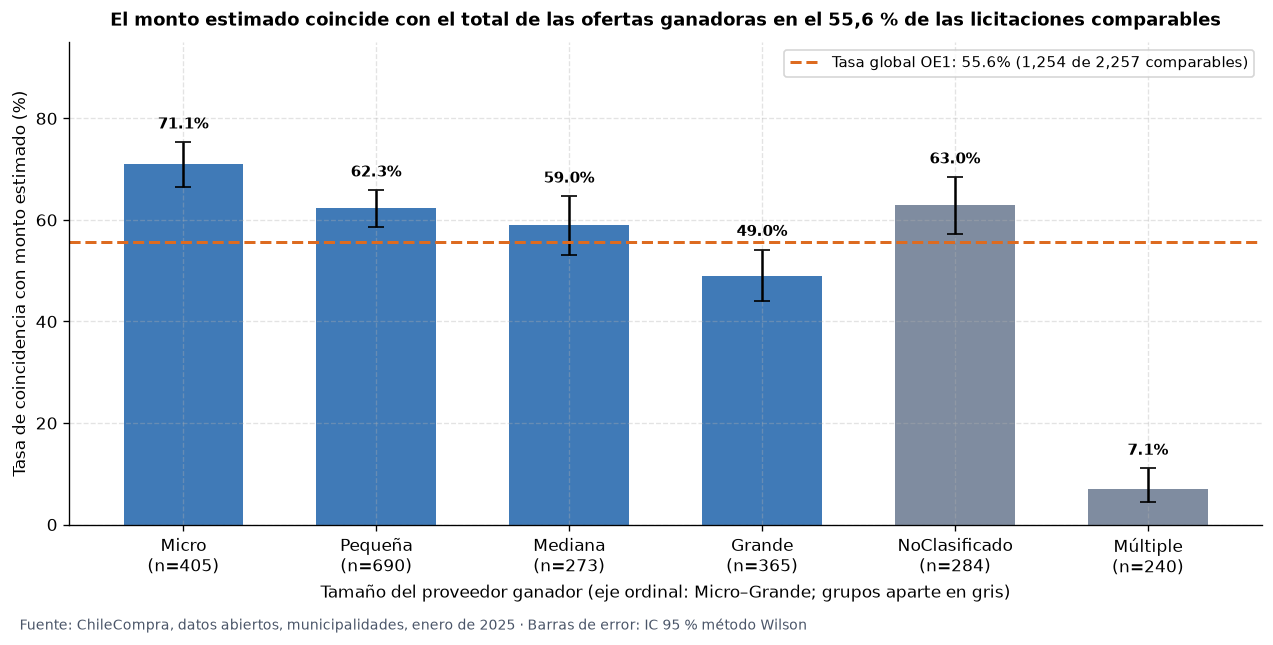

Figura 1 guardada (200 ppp): F4\figuras\01_coincidencia_por_tamano.png


In [6]:
# 5.1 Figura 1 (OE1 contexto + OE3): barras de coincidencia por tamaño con IC Wilson y referencia 55,6 %.
n_comp_total = len(copia_graficar)
n_coinc_total = int(copia_graficar["CoincideConEstimado"].astype(bool).sum())
tasa_global_pct = (n_coinc_total / n_comp_total) * 100.0
ic_global_inf, ic_global_sup = intervalo_wilson(n_coinc_total, n_comp_total)
print(
    f"Contexto OE1: {n_coinc_total:,} de {n_comp_total:,} licitaciones coinciden "
    f"({tasa_global_pct:.2f} %, IC 95 % Wilson [{ic_global_inf*100:.2f} %, {ic_global_sup*100:.2f} %])."
)

tabla_tamano_global = tabla_resumen_por_tamano(copia_graficar, moneda=None)
display(tabla_tamano_global[["TamanoGanador", "Licitaciones", "Coinciden", "TasaCoincidenciaPct", "IC95_InfPct", "IC95_SupPct"]].round(2))

fig1 = graficar_coincidencia_por_tamano(
    tabla_tamano_global,
    tasa_global_pct=tasa_global_pct,
    n_global=(n_coinc_total, n_comp_total),
)
display(fig1)
ruta_fig1 = guardar_figura(fig1, carpeta_figuras / "01_coincidencia_por_tamano.png", dpi=200)
print("Figura 1 guardada (200 ppp):", ruta_fig1.relative_to(raiz))


**Lectura (Figura 1).** La línea naranja discontinua responde al **Objetivo 1**: de **`2.257` licitaciones comparables**, en **`1.254` (`55,6 %`)** el monto estimado registrado coincide con el total de las ofertas ganadoras, resultado destacado directamente en el título. Las barras por tamaño del proveedor ganador responden a la parte del **Objetivo 3** que compara la **coincidencia** (`71,1 %` en `Micro`, `62,3 %` en `Pequeña`, `59,0 %` en `Mediana`, `49,0 %` en `Grande`, `63,0 %` en `NoClasificado` y `7,1 %` en `Múltiple`, `n = 240`). Para completar el **Objetivo 3**, la variación de la **brecha** según el tamaño del proveedor se presenta en la **Sección 5.3 (Figura 3)** y se contrasta en la **Sección 8.2**.

,MonedaLicitacion,Licitaciones,BajoEstimado,BajoEstimadoPct,Coincide,CoincidePct,IC95_InfPct,IC95_SupPct,SobreEstimado,SobreEstimadoPct
0,CLP,2230,520,23.32,1252,56.14,54.08,58.19,458,20.54
1,CLF,20,15,75.00,0,0.00,0.00,16.11,5,25.00
2,UTM,4,3,75.00,0,0.00,0.00,48.99,1,25.00
3,USD,3,1,33.33,2,66.67,20.77,93.85,0,0.00


,MonedaLicitacion,Licitaciones,CoincidePct,MedianaBrecha,Q1_Brecha,Q3_Brecha,IQR_Brecha,MedianaRazon,IQR_Razon,MedianaLogRazon,Q1_LogRazon,Q3_LogRazon,IQR_LogRazon
0,CLP,2230,56.1435,0.00,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000
1,CLF,20,0.0000,-60.36,-601.3150,120.9952,722.3102,0.8404,0.3584,-0.1738,-0.3886,0.0349,0.4235
2,UTM,4,0.0000,-31.64,-2356.5875,0.2631,2356.8506,0.9197,0.8308,-0.0874,-0.9032,0.2649,1.1681
3,USD,3,66.6667,0.00,-0.4120,0.0000,0.4120,1.0000,0.4120,0.0000,-0.8686,0.0000,0.8686


Licitaciones con razón en [0,835; 0,845] (entorno de 1/1,19 ≈ 0,8403): 234 de 539 bajo el estimado (43.4 %).


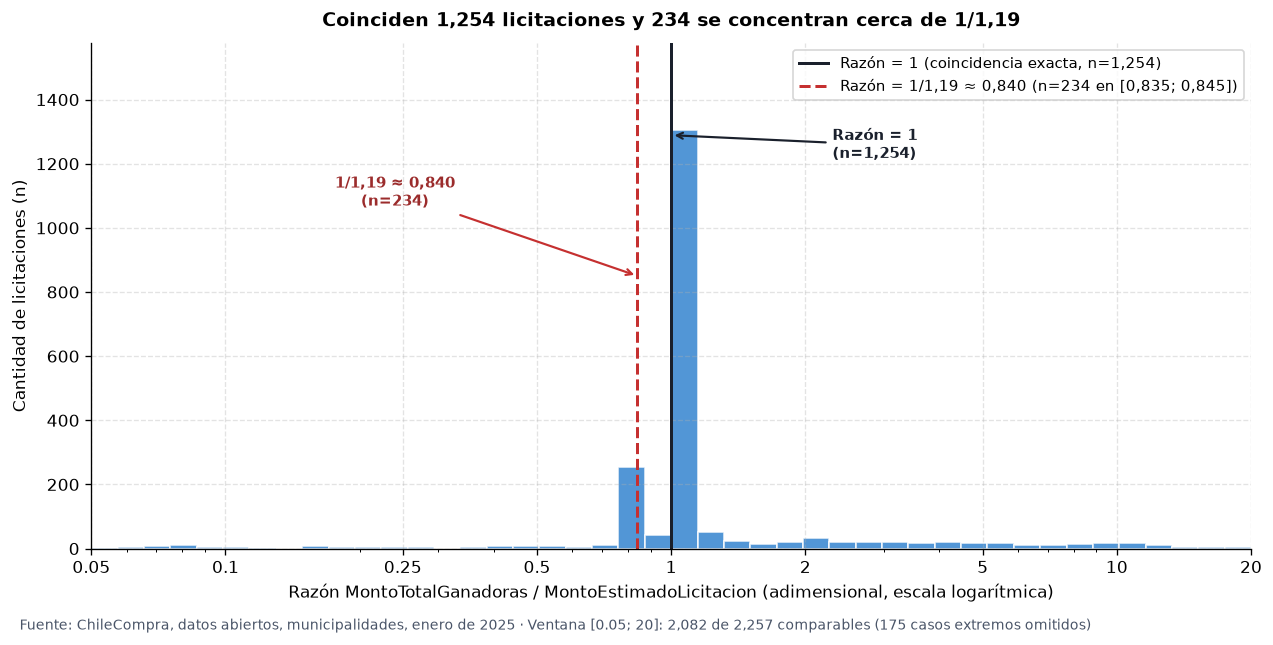

Figura 2 guardada (200 ppp): F4\figuras\02_razon_ganador_estimado_log.png


In [7]:
# 5.2 Figura 2 (OE2): histograma de razón ganador/estimado en escala logarítmica con marcas en 1 y 1/1,19.
tabla_sentido_mon = resumen_sentido_por_moneda(copia_graficar)
tabla_magnitud_mon = resumen_magnitud_por_moneda(copia_graficar)
display(tabla_sentido_mon.round(2))
display(tabla_magnitud_mon.round(4))

n_cerca_iva = int(((copia_graficar["RazonMonto"] >= 0.835) & (copia_graficar["RazonMonto"] <= 0.845)).sum())
n_bajo_total = int(copia_graficar["SentidoBrecha"].eq("Bajo el estimado").sum())
print(f"Licitaciones con razón en [0,835; 0,845] (entorno de 1/1,19 ≈ 0,8403): {n_cerca_iva:,} de {n_bajo_total:,} bajo el estimado ({n_cerca_iva/n_bajo_total*100:.1f} %).")

fig2 = graficar_razon_escala_log(copia_graficar)
display(fig2)
ruta_fig2 = guardar_figura(fig2, carpeta_figuras / "02_razon_ganador_estimado_log.png", dpi=200)
print("Figura 2 guardada (200 ppp):", ruta_fig2.relative_to(raiz))


**Lectura (Figura 2).** La ventana [0,835, 0,845] contiene el valor teórico 1/1,19. La sección de feedback cuantifica el agrupamiento por moneda y evalúa cuánto cambian las cifras bajo un supuesto explícito de IVA.

,TamanoGanador,Licitaciones,BajoEstimadoPct,TasaCoincidenciaPct,SobreEstimadoPct,MedianaBrecha,MedianaRazon,IQR_Razon
0,Micro,405,18.02,71.11,10.86,0.0,1.00,0.00
1,Pequeña,690,27.39,62.32,10.29,0.0,1.00,0.16
2,Mediana,273,29.67,58.97,11.36,0.0,1.00,0.16
3,Grande,365,25.21,49.04,25.75,0.0,1.00,0.04
4,NoClasificado,284,26.41,63.03,10.56,0.0,1.00,0.02
5,Múltiple,240,12.08,7.08,80.83,7153360.0,2.51,4.24


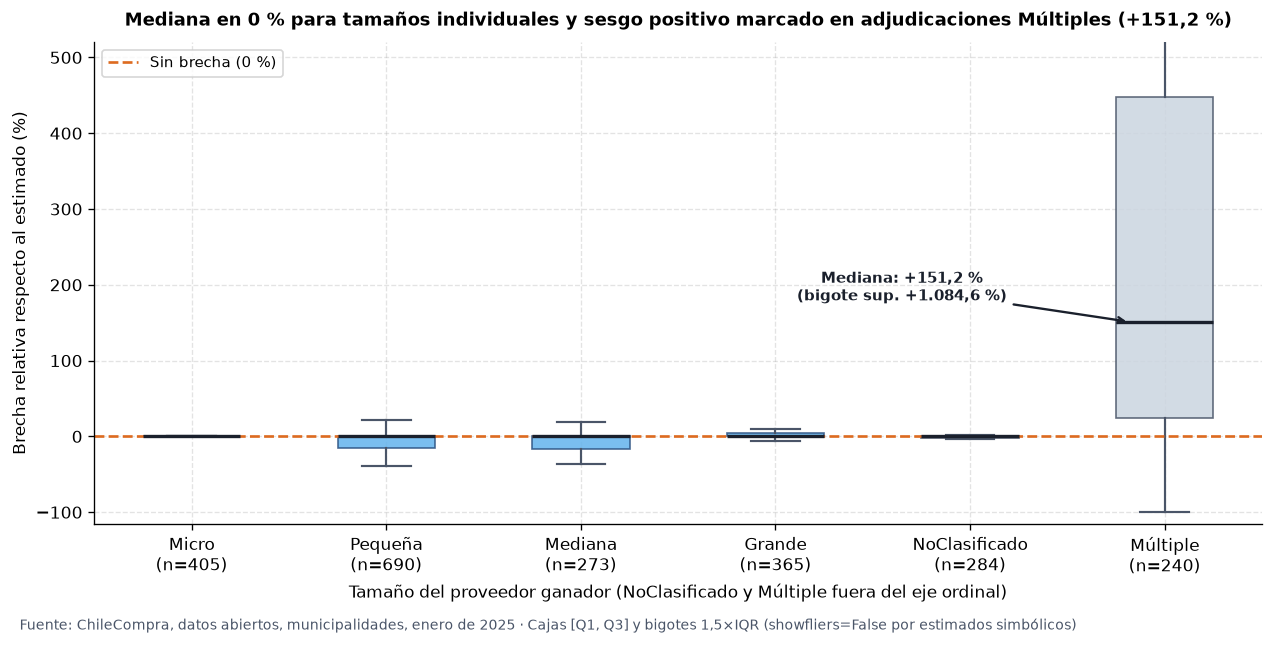

Figura 3 guardada (200 ppp): F4\figuras\03_cajas_brecha_relativa_tamano.png


In [8]:
# 5.3 Figura 3 (OE3): cajas de brecha relativa (%) por tamaño ganador con n por categoría.
cols_brecha = ["TamanoGanador", "Licitaciones", "BajoEstimadoPct", "TasaCoincidenciaPct", "SobreEstimadoPct", "MedianaBrecha", "MedianaRazon", "IQR_Razon"]
display(tabla_resumen_por_tamano(copia_graficar, moneda=None)[cols_brecha].round(2))

fig3 = graficar_cajas_brecha_relativa(copia_graficar)
display(fig3)
ruta_fig3 = guardar_figura(fig3, carpeta_figuras / "03_cajas_brecha_relativa_tamano.png", dpi=200)
print("Figura 3 guardada (200 ppp):", ruta_fig3.relative_to(raiz))


**Lectura (Figura 3).** Este gráfico complementa el **Objetivo 3** comparando cómo varía la **brecha relativa** según el tamaño del proveedor ganador (mientras la Figura 1 compara la tasa de coincidencia). La mediana de la brecha es **`0 %` de `Micro` a `Grande`**, aunque `Pequeña` (`Q1 = -15,6 %`) y `Mediana` (`Q1 = -16,0 %`) se extienden hacia el umbral de `-15,97 %` (`1/1,19 - 1`) y **`Grande` (`Q3 = +4,2 %`)** se desplaza hacia brechas positivas. En las adjudicaciones **`Múltiple` (`n = 240`)**, el total de las ofertas ganadoras quedó **`+151,2 %` por encima del estimado en la mediana** (`IQR = 424,4 pp`), como señala la flecha sobre la línea de mediana dentro de la caja.

## 6. Control de variable de confusión: tamaño dentro de tramos de monto

Una explicación alternativa de la caída observada en la Figura 1 (`Micro 71,1 %` frente a `Grande 49,0 %`) es que las empresas grandes adjudican procesos de mayor presupuesto, donde es más difícil coincidir exactamente con el estimado. Para probar esta hipótesis de confusión, se estratifica `TamanoGanador` dentro de cada **`TramoEstimado`** en `CLP` (`n = 1.710` licitaciones comparables con tamaño único clasificado) mediante `tabla_control_confusion()`.


In [9]:
# 6) Control de confusión: coincidencia por tamaño ganador dentro de cada tramo de monto estimado (CLP).
tabla_confusion = tabla_control_confusion(copia_graficar, moneda="CLP")
pivote_tasa = tabla_confusion.pivot(index="TramoEstimado", columns="TamanoGanador", values="TasaCoincidenciaPct").reindex(
    index=["Hasta 1 M CLP", "1 a 10 M CLP", "10 a 50 M CLP", "Más de 50 M CLP"],
    columns=list(ORDEN_TAMANO),
)
pivote_n = tabla_confusion.pivot(index="TramoEstimado", columns="TamanoGanador", values="Licitaciones").reindex(
    index=["Hasta 1 M CLP", "1 a 10 M CLP", "10 a 50 M CLP", "Más de 50 M CLP"],
    columns=list(ORDEN_TAMANO),
)
pivote_tasa["Brecha Micro - Grande (pp)"] = pivote_tasa["Micro"] - pivote_tasa["Grande"]
assert (pivote_tasa["Brecha Micro - Grande (pp)"] > 0).all(), "Micro debe superar a Grande en todos los tramos"

print(f"[OK] Control estratificado sobre {int(tabla_confusion['Licitaciones'].sum()):,} licitaciones CLP (categorías ordinales).")
print("Tasa de coincidencia (%) por tramo y tamaño:")
display(pivote_tasa.round(1))
print("Tamaño muestral (n) por celda:")
display(pivote_n)


[OK] Control estratificado sobre 1,710 licitaciones CLP (categorías ordinales).
Tasa de coincidencia (%) por tramo y tamaño:


TamanoGanador,Micro,Pequeña,Mediana,Grande,Brecha Micro - Grande (pp)
TramoEstimado,,,,,
Hasta 1 M CLP,87.7,68.1,73.7,46.2,41.5
1 a 10 M CLP,65.4,58.7,56.4,45.8,19.6
10 a 50 M CLP,71.0,64.1,51.6,56.1,14.9
Más de 50 M CLP,67.4,63.8,64.5,54.0,13.5


Tamaño muestral (n) por celda:


TamanoGanador,Micro,Pequeña,Mediana,Grande
TramoEstimado,,,,
Hasta 1 M CLP,73,91,38,65
1 a 10 M CLP,156,201,78,120
10 a 50 M CLP,131,259,93,107
Más de 50 M CLP,43,130,62,63


**Conclusión del control de confusión.** La ventaja de `Micro` sobre `Grande` **se mantiene en los cuatro tramos de monto**: `+41,5 pp` en procesos `Hasta 1 M CLP` (`87,7 %` vs. `46,2 %`), `+19,6 pp` en `1 a 10 M CLP` (`65,4 %` vs. `45,8 %`), `+14,9 pp` en `10 a 50 M CLP` (`71,0 %` vs. `56,1 %`) y `+13,5 pp` en `Más de 50 M CLP` (`67,4 %` vs. `54,0 %`). Por tanto, el monto estimado no explica por sí solo la diferencia observada por tamaño del proveedor ganador.


## 7. Registro trazable de hallazgos (`docs/hallazgos_f4.csv`) y metadatos (`docs/metadatos_f4.json`)

Exporta [`docs/hallazgos_f4.csv`](../docs/hallazgos_f4.csv) indicando explícitamente para cada cifra clave la sección exacta del cuaderno que la produce (fuente única para el informe y el video), y actualiza [`docs/metadatos_f4.json`](../docs/metadatos_f4.json) con las tres figuras (`200 ppp`) y el control de confusión.


In [10]:
# 7) Generar docs/hallazgos_f4.csv y actualizar docs/metadatos_f4.json.
registros_hallazgos = [
    {"Id": "OE1_comparables", "Seccion_notebook": "Sección 4 / 5", "Objetivo_F1": "OE1", "Indicador": "Licitaciones comparables", "Grupo_o_alcance": "Global", "Valor": len(copia_graficar), "Unidad": "licitaciones", "N": len(licitaciones_f4), "Nota": "EstadoBrecha == Calculada de 2.292 totales"},
    {"Id": "OE1_coincidencia_n", "Seccion_notebook": "Sección 5 (contexto OE1)", "Objetivo_F1": "OE1", "Indicador": "Licitaciones que coinciden", "Grupo_o_alcance": "Global", "Valor": n_coinc_total, "Unidad": "licitaciones", "N": n_comp_total, "Nota": "Tolerancia F2 <= 1e-8"},
    {"Id": "OE1_coincidencia_pct", "Seccion_notebook": "Sección 5 (contexto OE1)", "Objetivo_F1": "OE1", "Indicador": "Tasa de coincidencia global", "Grupo_o_alcance": "Global", "Valor": round(tasa_global_pct, 2), "Unidad": "%", "N": n_comp_total, "Nota": f"IC 95 % Wilson [{ic_global_inf*100:.2f} %, {ic_global_sup*100:.2f} %]"},
]

for _, f_sent in tabla_sentido_mon.iterrows():
    m = f_sent["MonedaLicitacion"]
    registros_hallazgos.append({
        "Id": f"OE2_coincidencia_{m}", "Seccion_notebook": "Sección 5.2", "Objetivo_F1": "OE1 / OE2",
        "Indicador": "Tasa de coincidencia por moneda", "Grupo_o_alcance": m,
        "Valor": round(float(f_sent["CoincidePct"]), 2), "Unidad": "%", "N": int(f_sent["Licitaciones"]),
        "Nota": f"Bajo: {int(f_sent['BajoEstimado'])}, Coincide: {int(f_sent['Coincide'])}, Sobre: {int(f_sent['SobreEstimado'])}",
    })

registros_hallazgos.append({
    "Id": "OE2_razon_iva_1_19", "Seccion_notebook": "Sección 5.2 (Figura 2)", "Objetivo_F1": "OE2",
    "Indicador": "Licitaciones cercanas a razón 1/1,19", "Grupo_o_alcance": "RazonMonto en [0,835; 0,845]",
    "Valor": n_cerca_iva, "Unidad": "licitaciones", "N": n_bajo_total,
    "Nota": f"{n_cerca_iva / n_bajo_total * 100:.2f} % de las adjudicadas bajo el estimado (ventana compatible con IVA 19 %)",
})

for _, f_tam in tabla_tamano_global.iterrows():
    t = f_tam["TamanoGanador"]
    registros_hallazgos.append({
        "Id": f"OE3_coincidencia_{t}", "Seccion_notebook": "Sección 5.1 (Figura 1)", "Objetivo_F1": "OE3",
        "Indicador": "Tasa de coincidencia por tamaño", "Grupo_o_alcance": t,
        "Valor": round(float(f_tam["TasaCoincidenciaPct"]), 2), "Unidad": "%", "N": int(f_tam["Licitaciones"]),
        "Nota": f"IC 95 % Wilson [{f_tam['IC95_InfPct']:.2f} %, {f_tam['IC95_SupPct']:.2f} %]",
    })
    med_rel = float((f_tam["MedianaRazon"] - 1.0) * 100.0)
    q1_rel = float(copia_graficar.loc[copia_graficar["TamanoGanador"].eq(t), "BrechaRelativaPct"].quantile(0.25))
    q3_rel = float(copia_graficar.loc[copia_graficar["TamanoGanador"].eq(t), "BrechaRelativaPct"].quantile(0.75))
    registros_hallazgos.append({
        "Id": f"OE3_brecha_rel_{t}", "Seccion_notebook": "Sección 5.3 (Figura 3)", "Objetivo_F1": "OE3",
        "Indicador": "Mediana de brecha relativa", "Grupo_o_alcance": t,
        "Valor": round(med_rel, 2), "Unidad": "%", "N": int(f_tam["Licitaciones"]),
        "Nota": f"Q1={q1_rel:.2f} %, Q3={q3_rel:.2f} %, IQR={q3_rel - q1_rel:.2f} pp",
    })

for tramo, fila_p in pivote_tasa.iterrows():
    registros_hallazgos.append({
        "Id": f"CONF_brecha_{tramo}", "Seccion_notebook": "Sección 6", "Objetivo_F1": "Control de confusión",
        "Indicador": "Diferencia Micro - Grande dentro del tramo", "Grupo_o_alcance": f"CLP · {tramo}",
        "Valor": round(float(fila_p["Brecha Micro - Grande (pp)"]), 2), "Unidad": "puntos porcentuales",
        "N": int(pivote_n.loc[tramo].sum()),
        "Nota": f"Micro={fila_p['Micro']:.1f} % vs Grande={fila_p['Grande']:.1f} %",
    })

df_hallazgos = pd.DataFrame(registros_hallazgos)
ruta_hallazgos = raiz / "docs/hallazgos_f4.csv"
df_hallazgos.to_csv(ruta_hallazgos, sep=";", encoding="utf-8-sig", index=False, lineterminator="\n")

metadatos_f4 = {
    "fase": "F4",
    "etapa": "Figuras por objetivo (200 ppp), control de confusión y hallazgos_f4.csv",
    "entorno": {
        "python": platform.python_version(),
        "sistema": platform.system(),
        "entorno_virtual_activo": bool(sys.prefix != sys.base_prefix),
        "paquetes": {
            fila["Paquete"]: {"instalada": fila["Instalada"], "declarada": fila["Declarada"], "coincide": bool(fila["Coincide"])}
            for _, fila in versiones_f4.iterrows()
        },
        "estilo_figuras_rcparams": ESTILO_FIGURAS_F4,
    },
    "artefactos": {
        "separador": ";",
        "ofertas": {"filas": int(len(ofertas_f4)), "columnas_archivo": len(cols_archivo_ofertas), "usecols": list(COLUMNAS_OFERTAS_F4)},
        "licitaciones": {"filas": int(len(licitaciones_f4)), "columnas_archivo": len(cols_archivo_lic), "usecols": list(COLUMNAS_LICITACIONES_F4)},
        "diccionario_filas": int(len(diccionario)),
        "parametros_filas": int(len(parametros)),
        "contrato_aprobado": True,
    },
    "verificacion_raw": verificacion_raw,
    "copia_graficar": {
        "filas_comparables": int(len(copia_graficar)),
        "columnas_agregadas": ["RazonMonto", "LogRazonMonto", "SentidoBrecha", "TamanoGanador", "TamanoGanadorOrdinal", "EtiquetaCoincidencia", "BrechaRelativaPct", "TramoEstimado"],
        "eje_ordinal": list(ORDEN_TAMANO),
        "fuera_del_eje_ordinal": ["NoClasificado", "Múltiple"],
        "conteos_por_moneda": {str(k): int(v) for k, v in copia_graficar["MonedaLicitacion"].value_counts().items()},
        "conteos_por_tramo": {str(k): int(v) for k, v in copia_graficar["TramoEstimado"].value_counts(sort=False).items()},
    },
    "figuras_200ppp": {
        "dpi": 200,
        "versionadas_en_git": False,
        "archivos_locales": [
            str(ruta_fig1.relative_to(raiz)).replace("\\", "/"),
            str(ruta_fig2.relative_to(raiz)).replace("\\", "/"),
            str(ruta_fig3.relative_to(raiz)).replace("\\", "/"),
        ],
    },
    "control_confusion": {
        "variable_confusora": "TramoEstimado (CLP)",
        "licitaciones_evaluadas": int(tabla_confusion["Licitaciones"].sum()),
        "brecha_micro_vs_grande_pp": {str(idx): round(float(val), 2) for idx, val in pivote_tasa["Brecha Micro - Grande (pp)"].items()},
    },
    "hallazgos_csv": "docs/hallazgos_f4.csv",
    "hallazgos_filas": int(len(df_hallazgos)),
}
ruta_metadatos = raiz / "docs/metadatos_f4.json"
ruta_metadatos.write_text(json.dumps(metadatos_f4, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")

print(f"[OK] {ruta_hallazgos.relative_to(raiz)} generado ({len(df_hallazgos)} cifras con sección de origen).")
print(f"[OK] {ruta_metadatos.relative_to(raiz)} actualizado.")
display(df_hallazgos[["Id", "Seccion_notebook", "Objetivo_F1", "Grupo_o_alcance", "Valor", "Unidad", "N"]])


[OK] docs\hallazgos_f4.csv generado (24 cifras con sección de origen).
[OK] docs\metadatos_f4.json actualizado.


,Id,Seccion_notebook,Objetivo_F1,Grupo_o_alcance,Valor,Unidad,N
0,OE1_comparables,Sección 4 / 5,OE1,Global,2257.00,licitaciones,2292
1,OE1_coincidencia_n,Sección 5 (contexto OE1),OE1,Global,1254.00,licitaciones,2257
2,OE1_coincidencia_pct,Sección 5 (contexto OE1),OE1,Global,55.56,%,2257
3,OE2_coincidencia_CLP,Sección 5.2,OE1 / OE2,CLP,56.14,%,2230
4,OE2_coincidencia_CLF,Sección 5.2,OE1 / OE2,CLF,0.00,%,20
5,OE2_coincidencia_UTM,Sección 5.2,OE1 / OE2,UTM,0.00,%,4
6,OE2_coincidencia_USD,Sección 5.2,OE1 / OE2,USD,66.67,%,3
7,OE2_razon_iva_1_19,Sección 5.2 (Figura 2),OE2,"RazonMonto en [0,835; 0,845]",234.00,licitaciones,539
8,OE3_coincidencia_Micro,Sección 5.1 (Figura 1),OE3,Micro,71.11,%,405
9,OE3_brecha_rel_Micro,Sección 5.3 (Figura 3),OE3,Micro,0.00,%,405


## 8. Feedback S2 · Sensibilidad de OE2 y OE3

La unidad es la licitación identificada por `NroLicitacion`. La base incluye una fila por código con `EstadoBrecha = Calculada`, un estimado positivo y consistente, y ganadoras con montos positivos y finitos en la misma moneda que el estimado. Los montos de las líneas ganadoras se suman. Se conserva la tolerancia de coincidencia original de 10⁻⁸ en la unidad monetaria. No se convierten monedas.

En F3, `marcar_duplicados` aplica `duplicated(keep=False)` a la fila cruda completa antes de convertir tipos. Marca **44 filas**. El conteo de **22** corresponde a las copias adicionales de esos grupos. Se comparan tres muestras, con los datos registrados, conservando la primera fila de cada grupo idéntico y retirando las 44 filas marcadas. En los dos últimos escenarios se recalculan los totales ganadores, la comparabilidad y el tamaño desde las ofertas restantes. Las líneas idénticas pueden corresponder a adjudicaciones legítimas.


In [11]:
from src.comunicacion import (
    comparar_muestras_feedback, magnitud_por_sentido, pruebas_por_tamano,
    sensibilidad_iva, tasa_por_grupo, tasas_exclusion_tamano,
)
from src.preprocesamiento import cargar_csv, marcar_duplicados

marcas = ofertas_f4["EsDuplicadoPotencial"]
assert marcas.sum() == 44
copias = None
if ruta_raw.is_file():
    crudo_f4 = cargar_csv(ruta_raw)
    marcas_raw = marcar_duplicados(crudo_f4)[0]["EsDuplicadoPotencial"]
    assert marcas_raw.tolist() == marcas.tolist()
    copias = crudo_f4.duplicated(keep="first")
    assert copias.sum() == 22
    assert normalizar_codigo(crudo_f4["NroLicitacion"]).tolist() == normalizar_codigo(
        ofertas_f4["NroLicitacion"]).tolist()
else:
    print("Sin CSV crudo, se omite el escenario que conserva la primera fila idéntica.")

muestras_s2 = comparar_muestras_feedback(licitaciones_f4, ofertas_f4, copias)
original_s2 = muestras_s2["Original"]
print(f"{marcas.sum()} filas marcadas en {ofertas_f4.loc[marcas, 'NroLicitacion'].nunique()} licitaciones.")
base_s2 = original_s2.set_index("NroLicitacion")
for nombre, muestra in muestras_s2.items():
    actual = muestra.set_index("NroLicitacion")
    perdidas = base_s2.index.difference(actual.index)
    nuevas = actual.index.difference(base_s2.index)
    comunes = base_s2.index.intersection(actual.index)
    cambiadas = ~base_s2.loc[comunes, "RazonMonto"].sub(actual.loc[comunes, "RazonMonto"]).abs().le(1e-12)
    print(f"{nombre}. Salen {len(perdidas)}, entran {len(nuevas)}, cambia la razón en {cambiadas.sum()}.")
display(pd.DataFrame({nombre: muestra["MonedaLicitacion"].value_counts()
                      for nombre, muestra in muestras_s2.items()}))


44 filas marcadas en 10 licitaciones.
Original. Salen 0, entran 0, cambia la razón en 0.
Sin copias adicionales. Salen 0, entran 0, cambia la razón en 4.
Sin filas marcadas. Salen 0, entran 0, cambia la razón en 4.


,Original,Sin copias adicionales,Sin filas marcadas
MonedaLicitacion,,,
CLP,2230,2230,2230
CLF,20,20,20
UTM,4,4,4
USD,3,3,3


### 8.1. OE2 · Razón, logaritmo y base tributaria

La razón es total ganador dividido por estimado. Se usa el logaritmo natural y se informa la mediana y el IQR (Q3 − Q1) dentro de cada moneda y sentido. Los porcentajes usan todas las licitaciones comparables de la moneda y muestra correspondiente.

El [diccionario del proyecto](../docs/README.md) describe `MontoTotalOferta` como total neto de la línea y `MontoEstimadoLicitacion` como presupuesto total. La definición del estimado carece de una etiqueta tributaria por registro. Se compara la ventana [0,835, 0,845] con bandas inmediatas de igual ancho y con una tolerancia de 0,0001 alrededor de 1/1,19. Un pico estrecho respalda la hipótesis de bases tributarias distintas. También puede reflejar reglas de registro o fijación del estimado.

En el escenario ajustado se multiplica el ganador por 1,19 únicamente en CLP dentro de la ventana y cuando el resultado queda a un peso o menos del estimado. Se considera coincidencia dentro de esa tolerancia de redondeo y se conserva el residuo para calcular razón y brecha. Los demás casos conservan la regla original. El resultado es condicional al supuesto de IVA y a la ventana elegida.


In [12]:
for nombre, muestra in muestras_s2.items():
    evidencia_iva, ajuste_iva = sensibilidad_iva(muestra)
    print(nombre)
    display(evidencia_iva.round(3))
    for escenario, datos in {"Montos registrados": muestra, "Escenario IVA": ajuste_iva}.items():
        print(escenario)
        display(magnitud_por_sentido(datos).round(5))
        display(resumen_magnitud_por_moneda(datos).round(5))


Original


,MonedaLicitacion,N,CercaIVA,BandaInferior,BandaSuperior,CercaIVAEstricta,AjustablesCLP,CercaIVAPct
0,CLF,20,5,0,0,1,0,25.000
1,CLP,2230,228,2,1,219,213,10.224
2,USD,3,0,0,0,0,0,0.000
3,UTM,4,1,0,0,1,0,25.000


Montos registrados


,Moneda,Sentido,N,PctMoneda,Mediana_BrechaMonto,IQR_BrechaMonto,Mediana_RazonMonto,IQR_RazonMonto,Mediana_LogRazonMonto,IQR_LogRazonMonto
0,CLF,Bajo el estimado,15,75.00000,-2.620000e+02,1.481850e+03,0.83966,0.43163,-0.17475,0.86668
1,CLF,Coincide,0,0.00000,NaN,NaN,NaN,NaN,NaN,NaN
2,CLF,Sobre el estimado,5,25.00000,1.065000e+03,3.710500e+02,1.72746,0.69197,0.54665,0.45832
3,CLP,Bajo el estimado,520,23.31839,-5.979634e+06,1.671808e+07,0.84034,0.80458,-0.17395,3.15723
4,CLP,Coincide,1252,56.14350,0.000000e+00,0.000000e+00,1.00000,0.00000,0.00000,0.00000
5,CLP,Sobre el estimado,458,20.53812,5.351202e+06,2.164852e+07,2.88335,5.70906,1.05891,1.61897
6,USD,Bajo el estimado,1,33.33333,-8.240000e-01,0.000000e+00,0.17600,0.00000,-1.73727,0.00000
7,USD,Coincide,2,66.66667,0.000000e+00,0.000000e+00,1.00000,0.00000,0.00000,0.00000
8,USD,Sobre el estimado,0,0.00000,NaN,NaN,NaN,NaN,NaN,NaN
9,UTM,Bajo el estimado,3,75.00000,-6.300000e+01,4.618535e+03,0.84034,0.47683,-0.17395,1.54508


,MonedaLicitacion,Licitaciones,CoincidePct,MedianaBrecha,Q1_Brecha,Q3_Brecha,IQR_Brecha,MedianaRazon,IQR_Razon,MedianaLogRazon,Q1_LogRazon,Q3_LogRazon,IQR_LogRazon
0,CLP,2230,56.14350,0.00,0.0000,0.00000,0.00000,1.00000,0.00000,0.00000,0.00000,0.00000,0.00000
1,CLF,20,0.00000,-60.36,-601.3150,120.99523,722.31023,0.84045,0.35838,-0.17382,-0.38861,0.03485,0.42346
2,UTM,4,0.00000,-31.64,-2356.5875,0.26310,2356.85060,0.91973,0.83083,-0.08742,-0.90323,0.26486,1.16809
3,USD,3,66.66667,0.00,-0.4120,0.00000,0.41200,1.00000,0.41200,0.00000,-0.86864,0.00000,0.86864


Escenario IVA


... (14 outputs left out)

,MonedaLicitacion,Licitaciones,CoincidePct,MedianaBrecha,Q1_Brecha,Q3_Brecha,IQR_Brecha,MedianaRazon,IQR_Razon,MedianaLogRazon,Q1_LogRazon,Q3_LogRazon,IQR_LogRazon
0,CLP,2230,56.14350,0.00,0.0000,0.00000,0.00000,1.00000,0.00000,0.00000,0.00000,0.00000,0.00000
1,CLF,20,0.00000,-60.36,-601.3150,120.99523,722.31023,0.84045,0.35838,-0.17382,-0.38861,0.03485,0.42346
2,UTM,4,0.00000,-31.64,-2356.5875,0.26310,2356.85060,0.91973,0.83083,-0.08742,-0.90323,0.26486,1.16809
3,USD,3,66.66667,0.00,-0.4120,0.00000,0.41200,1.00000,0.41200,0.00000,-0.86864,0.00000,0.86864


Escenario IVA


,Moneda,Sentido,N,PctMoneda,Mediana_BrechaMonto,IQR_BrechaMonto,Mediana_RazonMonto,IQR_RazonMonto,Mediana_LogRazonMonto,IQR_LogRazonMonto
0,CLF,Bajo el estimado,15,75.00000,-2.620000e+02,1.481850e+03,0.83966,0.43163,-0.17475,0.86668
1,CLF,Coincide,0,0.00000,NaN,NaN,NaN,NaN,NaN,NaN
2,CLF,Sobre el estimado,5,25.00000,1.065000e+03,3.710500e+02,1.72746,0.69197,0.54665,0.45832
3,CLP,Bajo el estimado,308,13.81166,-8.294500e+06,2.250729e+07,0.08333,0.71855,-2.48491,6.44726
4,CLP,Coincide,1465,65.69507,0.000000e+00,0.000000e+00,1.00000,0.00000,0.00000,0.00000
5,CLP,Sobre el estimado,457,20.49327,5.377199e+06,2.165053e+07,2.90886,5.70751,1.06776,1.61768
6,USD,Bajo el estimado,1,33.33333,-8.240000e-01,0.000000e+00,0.17600,0.00000,-1.73727,0.00000
7,USD,Coincide,2,66.66667,0.000000e+00,0.000000e+00,1.00000,0.00000,0.00000,0.00000
8,USD,Sobre el estimado,0,0.00000,NaN,NaN,NaN,NaN,NaN,NaN
9,UTM,Bajo el estimado,3,75.00000,-6.300000e+01,4.618535e+03,0.84034,0.47683,-0.17395,1.54508


,MonedaLicitacion,Licitaciones,CoincidePct,MedianaBrecha,Q1_Brecha,Q3_Brecha,IQR_Brecha,MedianaRazon,IQR_Razon,MedianaLogRazon,Q1_LogRazon,Q3_LogRazon,IQR_LogRazon
0,CLP,2230,65.69507,0.00,0.0000,0.00000,0.00000,1.00000,0.00000,0.00000,0.00000,0.00000,0.00000
1,CLF,20,0.00000,-60.36,-601.3150,120.99523,722.31023,0.84045,0.35838,-0.17382,-0.38861,0.03485,0.42346
2,UTM,4,0.00000,-31.64,-2356.5875,0.26310,2356.85060,0.91973,0.83083,-0.08742,-0.90323,0.26486,1.16809
3,USD,3,66.66667,0.00,-0.4120,0.00000,0.41200,1.00000,0.41200,0.00000,-0.86864,0.00000,0.86864


### 8.2. OE3 · Tamaño ganador, coincidencia y brecha relativa

Una licitación es **Múltiple** si sus filas ganadoras tienen tamaños distintos. **NoClasificado** indica que todas las ganadoras comparten esa etiqueta. Se presentan ambas exclusiones por separado y se compara con la muestra limitada a Micro, Pequeña, Mediana y Grande. OE3 usa los montos registrados.

Para los cuatro tamaños se calcula la tasa de coincidencia y su IC de Wilson del 95 %. El chi-cuadrado de Pearson contrasta independencia en una tabla 4 × 2 con tres grados de libertad. Se verifica que estén presentes los cuatro grupos y ambos resultados y que todas las frecuencias esperadas sean al menos cinco. Cada licitación contribuye una sola vez. La independencia entre licitaciones es un supuesto y puede verse limitada por organismos o proveedores recurrentes.

La brecha relativa es 100 × (razón − 1). Spearman usa rangos porque el tamaño tiene orden y las brechas son asimétricas, con empates y extremos. El contraste bilateral mide asociación monótona y su valor p es aproximado. Las pruebas incluyen los extremos.

El control por monto usa los cortes fijos del módulo en 1, 10 y 50 millones de CLP. El límite superior pertenece a cada tramo. Los cortes son reglas predefinidas, por lo que no requieren ajuste de un `Transformador`. Se comparan tasas y medianas dentro de cada tramo. El ancho de los tramos y otras características de las licitaciones pueden dejar confusión residual.


In [13]:
for nombre, muestra in muestras_s2.items():
    print(nombre)
    display(tasas_exclusion_tamano(muestra).round(3))
    ordinal_s2 = muestra.loc[muestra["TamanoGanadorOrdinal"].notna()]
    display(tasa_por_grupo(ordinal_s2, "TamanoGanador", "CoincideConEstimado",
                           orden=ORDEN_TAMANO)[["TamanoGanador", "N", "Exitos", "TasaPct",
                                               "IC_InfPct", "IC_SupPct"]].round(3))
    display(pruebas_por_tamano(muestra))
    display(tabla_control_confusion(muestra).round(3))


Original


,Filtro,N,Excluidas,Coinciden,TasaPct,Diferencia_vs_55_6_pp
0,Todas las comparables,2257,0,1254,55.560,-0.040
1,Sin Múltiple,2017,240,1237,61.329,5.729
2,Sin NoClasificado,1973,284,1075,54.486,-1.114
3,Solo tamaños ordinales,1733,524,1058,61.050,5.450


,TamanoGanador,N,Exitos,TasaPct,IC_InfPct,IC_SupPct
0,Micro,405,288,71.111,66.515,75.311
1,Pequeña,690,430,62.319,58.644,65.857
2,Mediana,273,161,58.974,53.054,64.645
3,Grande,365,179,49.041,43.949,54.153


,Prueba,N,Estadístico,p,Mínimo esperado
0,Chi-cuadrado de Pearson,1733,40.338893,9.030553e-09,106.332949
1,Spearman,1733,0.021115,3.796953e-01,NaN


,TramoEstimado,TamanoGanador,Licitaciones,Coinciden,TasaCoincidenciaPct,IC95_InfPct,IC95_SupPct,Brecha_Micro_vs_Grande_pp,MedianaBrechaRelativaPct
0,Hasta 1 M CLP,Micro,73,64,87.671,78.199,93.376,41.517,0.0
1,Hasta 1 M CLP,Pequeña,91,62,68.132,57.991,76.804,41.517,0.0
2,Hasta 1 M CLP,Mediana,38,28,73.684,57.991,85.029,41.517,0.0
3,Hasta 1 M CLP,Grande,65,30,46.154,34.590,58.147,41.517,0.0
4,1 a 10 M CLP,Micro,156,102,65.385,57.630,72.399,19.551,0.0
5,1 a 10 M CLP,Pequeña,201,118,58.706,51.799,65.288,19.551,0.0
6,1 a 10 M CLP,Mediana,78,44,56.410,45.362,66.857,19.551,0.0
7,1 a 10 M CLP,Grande,120,55,45.833,37.186,54.739,19.551,0.0
8,10 a 50 M CLP,Micro,131,93,70.992,62.711,78.077,14.918,0.0
9,10 a 50 M CLP,Pequeña,259,166,64.093,58.083,69.690,14.918,0.0


Sin copias adicionales


... (5 outputs left out)

,Filtro,N,Excluidas,Coinciden,TasaPct,Diferencia_vs_55_6_pp
0,Todas las comparables,2257,0,1254,55.560,-0.040
1,Sin Múltiple,2017,240,1237,61.329,5.729
2,Sin NoClasificado,1973,284,1075,54.486,-1.114
3,Solo tamaños ordinales,1733,524,1058,61.050,5.450


,TamanoGanador,N,Exitos,TasaPct,IC_InfPct,IC_SupPct
0,Micro,405,288,71.111,66.515,75.311
1,Pequeña,690,430,62.319,58.644,65.857
2,Mediana,273,161,58.974,53.054,64.645
3,Grande,365,179,49.041,43.949,54.153


,Prueba,N,Estadístico,p,Mínimo esperado
0,Chi-cuadrado de Pearson,1733,40.338893,9.030553e-09,106.332949
1,Spearman,1733,0.021115,3.796953e-01,NaN


,TramoEstimado,TamanoGanador,Licitaciones,Coinciden,TasaCoincidenciaPct,IC95_InfPct,IC95_SupPct,Brecha_Micro_vs_Grande_pp,MedianaBrechaRelativaPct
0,Hasta 1 M CLP,Micro,73,64,87.671,78.199,93.376,41.517,0.0
1,Hasta 1 M CLP,Pequeña,91,62,68.132,57.991,76.804,41.517,0.0
2,Hasta 1 M CLP,Mediana,38,28,73.684,57.991,85.029,41.517,0.0
3,Hasta 1 M CLP,Grande,65,30,46.154,34.590,58.147,41.517,0.0
4,1 a 10 M CLP,Micro,156,102,65.385,57.630,72.399,19.551,0.0
5,1 a 10 M CLP,Pequeña,201,118,58.706,51.799,65.288,19.551,0.0
6,1 a 10 M CLP,Mediana,78,44,56.410,45.362,66.857,19.551,0.0
7,1 a 10 M CLP,Grande,120,55,45.833,37.186,54.739,19.551,0.0
8,10 a 50 M CLP,Micro,131,93,70.992,62.711,78.077,14.918,0.0
9,10 a 50 M CLP,Pequeña,259,166,64.093,58.083,69.690,14.918,0.0


In [14]:
from IPython.display import Markdown

iva_original, _ = sensibilidad_iva(original_s2)
sin_marcas_s2 = muestras_s2["Sin filas marcadas"]
iva_sin, _ = sensibilidad_iva(sin_marcas_s2)
lineas = ["### 8.3. Qué cambia al retirar las filas marcadas", ""]
for moneda in ("CLP", "CLF", "UTM", "USD"):
    base = original_s2.loc[original_s2["MonedaLicitacion"].eq(moneda)]
    limpia = sin_marcas_s2.loc[sin_marcas_s2["MonedaLicitacion"].eq(moneda)]
    sentidos = [base["SentidoBrecha"].eq(sentido).sum() for sentido in ORDEN_SENTIDO]
    conteo_iva = iva_original.set_index("MonedaLicitacion").loc[moneda, "CercaIVA"]
    conteo_iva_limpia = iva_sin.set_index("MonedaLicitacion").loc[moneda, "CercaIVA"]
    cambio = "Las razones y los sentidos se mantienen." if (
        base.set_index("NroLicitacion")[["RazonMonto", "SentidoBrecha"]].sort_index().equals(
            limpia.set_index("NroLicitacion")[["RazonMonto", "SentidoBrecha"]].sort_index())
    ) else (f"La muestra queda en {len(limpia)} licitaciones, {conteo_iva_limpia} en la ventana "
            f"de IVA y {limpia['SentidoBrecha'].eq('Coincide').sum()} coincidentes.")
    lineas.append(f"- **{moneda}.** {len(base)} comparables, con {sentidos[0]} bajo el estimado, "
                  f"{sentidos[1]} coincidentes y {sentidos[2]} sobre el estimado. "
                  f"La mediana de razón es {base['RazonMonto'].median():.4f} y {conteo_iva} "
                  f"casos caen en la ventana de IVA. {cambio}")
for nombre, muestra in muestras_s2.items():
    iva, ajuste = sensibilidad_iva(muestra)
    es_clp = muestra["MonedaLicitacion"].eq("CLP")
    tasa_clp = 100 * muestra.loc[es_clp, "CoincideConEstimado"].mean()
    tasa_ajuste = 100 * ajuste.loc[es_clp, "CoincideConEstimado"].mean()
    tasas = tasas_exclusion_tamano(muestra)
    chi, spearman = pruebas_por_tamano(muestra).to_dict("records")
    diferencias = tabla_control_confusion(muestra).groupby(
        "TramoEstimado", sort=False)["Brecha_Micro_vs_Grande_pp"].first().tolist()
    lineas.extend(["", f"**{nombre}.** El escenario IVA reclasifica {iva['AjustablesCLP'].sum()} "
                   f"casos CLP. La coincidencia en CLP pasa de {tasa_clp:.2f} % a {tasa_ajuste:.2f} %. "
                   f"La tasa global con montos registrados es {tasas.iloc[0]['TasaPct']:.2f} % y "
                   f"entre tamaños ordinales es {tasas.iloc[-1]['TasaPct']:.2f} %. "
                   f"Chi-cuadrado p = {chi['p']:.3g}. Spearman ρ = {spearman['Estadístico']:+.3f}, "
                   f"p = {spearman['p']:.3g}. Las diferencias Micro menos Grande por tramo CLP "
                   f"son {', '.join(f'{d:+.2f}' for d in diferencias)} pp."])
lineas.extend(["", "Las monedas distintas de CLP tienen denominadores pequeños. Las pruebas "
               "son exploratorias y evalúan asociación. Los tramos aportan un control parcial "
               "por monto y la muestra cubre municipalidades de enero de 2025."])
display(Markdown("\n".join(lineas)))


### 8.3. Qué cambia al retirar las filas marcadas

- **CLP.** 2230 comparables, con 520 bajo el estimado, 1252 coincidentes y 458 sobre el estimado. La mediana de razón es 1.0000 y 228 casos caen en la ventana de IVA. La muestra queda en 2230 licitaciones, 228 en la ventana de IVA y 1252 coincidentes.
- **CLF.** 20 comparables, con 15 bajo el estimado, 0 coincidentes y 5 sobre el estimado. La mediana de razón es 0.8404 y 5 casos caen en la ventana de IVA. Las razones y los sentidos se mantienen.
- **UTM.** 4 comparables, con 3 bajo el estimado, 0 coincidentes y 1 sobre el estimado. La mediana de razón es 0.9197 y 1 casos caen en la ventana de IVA. Las razones y los sentidos se mantienen.
- **USD.** 3 comparables, con 1 bajo el estimado, 2 coincidentes y 0 sobre el estimado. La mediana de razón es 1.0000 y 0 casos caen en la ventana de IVA. Las razones y los sentidos se mantienen.

**Original.** El escenario IVA reclasifica 213 casos CLP. La coincidencia en CLP pasa de 56.14 % a 65.70 %. La tasa global con montos registrados es 55.56 % y entre tamaños ordinales es 61.05 %. Chi-cuadrado p = 9.03e-09. Spearman ρ = +0.021, p = 0.38. Las diferencias Micro menos Grande por tramo CLP son +41.52, +19.55, +14.92, +13.47 pp.

**Sin copias adicionales.** El escenario IVA reclasifica 213 casos CLP. La coincidencia en CLP pasa de 56.14 % a 65.70 %. La tasa global con montos registrados es 55.56 % y entre tamaños ordinales es 61.05 %. Chi-cuadrado p = 9.03e-09. Spearman ρ = +0.021, p = 0.38. Las diferencias Micro menos Grande por tramo CLP son +41.52, +19.55, +14.92, +13.47 pp.

**Sin filas marcadas.** El escenario IVA reclasifica 213 casos CLP. La coincidencia en CLP pasa de 56.14 % a 65.70 %. La tasa global con montos registrados es 55.56 % y entre tamaños ordinales es 61.05 %. Chi-cuadrado p = 9.03e-09. Spearman ρ = +0.021, p = 0.38. Las diferencias Micro menos Grande por tramo CLP son +41.52, +19.55, +14.92, +13.47 pp.

Las monedas distintas de CLP tienen denominadores pequeños. Las pruebas son exploratorias y evalúan asociación. Los tramos aportan un control parcial por monto y la muestra cubre municipalidades de enero de 2025.